### Imports

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

### Définitions

**CAH : classification ascendante hiérarchique**

Principe : autant de classes que d'individus (chaque individu forme un groupe), puis fusion des deux classes les plus proches, jusqu'à qu'il ne reste qu'un seul groupe.  
Résultat : arbre (dendogramme = historique des fusions) que l'on coupe à la hauteur voulue pour obtenir les classes.  

Ascendante car on part des individus pour remonter vers le groupe total & hiérarchique puisque chaque partition est emboîtée dans la suivante.

S'utilise sur des data de quelques milliers d'individus au max. et quand le nombre de classe est inconnu + besoin visualisation arbre.

Dans ce notebook, exemple d'une enseigne qui suit deux indicateurs clientèle :   
    - montant mensuel des achats  
    - nombre d'achats (par mois)

⇒ l'idée est de former des groupes de clients qui se ressemblent, tout en étant différents des autres groupes.
Une groupe se décrit en une phrase comme "petits paniers", "clients occasionnels", "clients fidèles".

Cette classification est dite non-supervisée car tout repose sur une mesure de ressemblance, pas d'étiquette connue en avance.

La distance entre deux individus est claire, on l'a calcule. Mais entre **deux groupes il faut une règle** = **méthode d'aggrégation**  

> quelle méthode ?   
> la méthode d'aggrégation en remplace pas la distance, elle s'appuie dessus pour comparer des groupes.  

DIAPO 25  
    - deux plus proches =  
    - deux plus éloignés =
    - 

### Construction d'une matrice des distances (euclidiennes)

#### Données d'exemple

>les variables :
>  
>individu = clients  
x = montant mensuel des achats (en dizaien de milliers)  
y = nombre d'achats par mois  

In [ ]:
data = {
    "Individu": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"],
    "x": [4, 1, 1, 10, 10, 6, 7, 13, 14, 16],
    "y": [3, 3, 4, 10, 8, 8, 9, 2, 6, 5]
}

df_base = pd.DataFrame(data).set_index("Individu")
display(df_base)

#### Distances euclidiennes (Pythagore):  

$$d(A,B)=\sqrt{(x_A-x_B)^2+(y_A-y_B)^2}$$

(A, B sont les deux clients comparés)  

⇒ si la distance est petite, il y a une forte ressemblance et inversement.  

Attention, avec une distance euclidienne, au choix des variables et à leur échelle, si besoin il faut standardiser les variables, pour que l'une n'écrase pas l'autre.   
Par exemple, la standardisation centrée-réduite transforme chaque variable en lui donnant une moyenne de 0 et un écart-type de 1.  
(standardiser n’est pas toujours souhaitable, si une variable doit réellement avoir plus d’importance pour l’analyse, il peut être pertinent de lui donner davantage de poids.)

In [ ]:
coordonnees = df_base[["x", "y"]].to_numpy()

distances = np.sqrt(
    ((coordonnees[:, None, :] - coordonnees[None, :, :]) ** 2).sum(axis=2)
)

print(distances)

#### Matrice symétrique des distances

Matrice symétrique + une diagonale (distance d’un individu à lui-même) = 0  
⇒ on en lit qu'un triangle (*cf* fonction numpy tril et triu (array, k-ieme diag) plus bas)

In [ ]:
matrice_distances = pd.DataFrame(
    distances,
    index=df_base.index,
    columns=df_base.index
)

display(matrice_distances.round(2))

### Méthode d'aggrégation : lien simple 

⇒ distance la plus petite entre un individu d'un groupe et un individu d'un autre (paire)

Comportement des groupes : peuvent se former en chaînes, en ajoutant successivement des individus proches les uns des autres  
Limite : effet de chaînage, peut réunir des groupes allongés ou peu compacts, même si leurs extrémités sont éloignées.

#### Identification individus les plus proches

##### Avec une boucle

In [ ]:
avec_boucle = matrice_distances.to_numpy()

distance_min = float("inf")
i_min, j_min = None, None

for i in range(len(avec_boucle)): # parcourt les lignes
    for j in range(i + 1, len(avec_boucle)): # parcourt les colonnes à droite de la diagonale
        if avec_boucle[i, j] < distance_min:
            distance_min = avec_boucle[i, j] # maj minimum
            i_min, j_min = i, j # attribution positions à la paire

if i_min is None or j_min is None:
    raise ValueError("Il faut au moins deux individus pour comparer les distances.")

a = matrice_distances.index[i_min]
b = matrice_distances.columns[j_min]

print(f"Plus proches : {a} et {b}, distance = {distance_min:.2f}")

##### Avec la fonction numpy triu // explications

Renvoie une copie d'un tableau - seulement le triangle supérieur - et les éléments situés sous la k-ième diagonale sont remplacés par zéro (k = diagonale de départ).  
(Pour les tableaux avec ndim supérieur à 2, triu s'appliquera aux deux derniers axes.)

In [ ]:
test = np.array([[1,2,3,10],[4,5,6,11],[7,8,9,13],[10,11,12,20]])

display(test)
display(np.triu(test, 0)) # garde le triangle supérieur AVEC la diagonale principale
display(np.triu(test, 1)) # garde le triangle supérieur SANS la diagonale principale
display(np.triu(test, -1)) # ou (test, 2) etc..

##### Avec la fonction numpy triu // application

In [ ]:
valeurs = matrice_distances.to_numpy()

i, j = np.triu_indices_from(valeurs, k=1)  # une seule moitié // symétrie et sans la diagonale principale de 0
# renvoie deux listes d’indices : i pour les lignes, j pour les colonnes

min = np.argmin(valeurs[i, j])

a = matrice_distances.index[i[min]]
b = matrice_distances.columns[j[min]]

print(f"Plus proches : {a} et {b}, distance = {valeurs[i[min], j[min]]:.2f}")

#### Fusions successives et actualisation de la matrice avec les nouveaux groupes

In [ ]:
D = matrice_distances.copy()
ordre_individus = list(df_base.index)
groupes = {individu: [individu] for individu in ordre_individus}
# dico où chaque individu = son propre groupe

while len(D) > 1: # jusqu'à qu'il ne reste qu'un groupe
    distances = D.to_numpy()
    i, j = np.triu_indices_from(distances, k=1)
    distance_min = np.argmin(distances[i, j])

    a = D.index[i[distance_min]]
    b = D.columns[j[distance_min]]
    distance = distances[i[distance_min], j[distance_min]]

    paire = sorted(groupes[a] + groupes[b],
                     key=ordre_individus.index)
    nouveau_groupe = "".join(paire)

    print(f"Fusion : {a} et {b} à la distance {distance:.2f}")

    reste = [groupe for groupe in D.index if groupe not in (a, b)]
    # liste des groupes qui ne participent pas à la fusion
    nouvelles_distances = {
        groupe: np.minimum(D.loc[a, groupe], D.loc[b, groupe])
        for groupe in reste
    }

    D = D.drop(index=[a, b], columns=[a, b])
    # retire de la matrice lignes et col des 2 groupe fusionnés

    D.loc[nouveau_groupe, reste] = [
        nouvelles_distances[groupe] for groupe in reste
    ]
    # ajoute une ligne pour le nouveau groupe et y inscrit ses distances aux autres groupes

    D.loc[reste, nouveau_groupe] = [
        nouvelles_distances[groupe] for groupe in reste
    ] 
    # ajoute la colonne

    D.loc[nouveau_groupe, nouveau_groupe] = 0
    # mais bien à 0 la distance du groupe avec lui-même

    groupes[nouveau_groupe] = paire
    del groupes[a]
    del groupes[b]
    # Màj dico 

    print("Matrice actualisée :")
    display(D.round(2))

#### Dendogramme // Historique des fusions

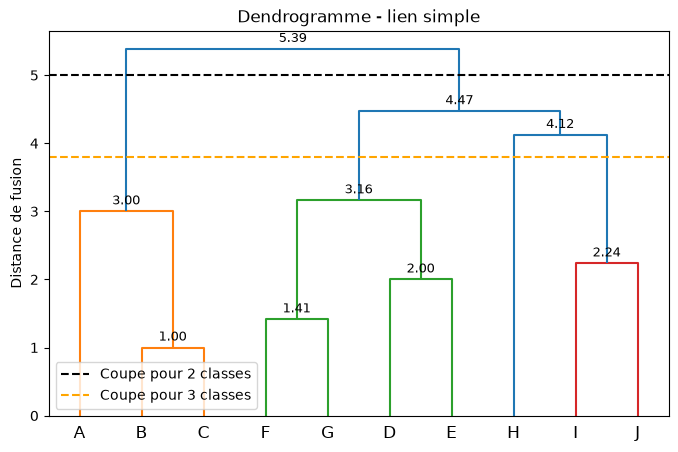

In [106]:
Z = linkage(coordonnees, method="single", metric="euclidean")

plt.figure(figsize=(8, 5))
resultat = dendrogram(Z, labels=df_base.index.tolist())

for x, y in zip(resultat["icoord"], resultat["dcoord"]):
    x_fusion = (x[1] + x[2]) / 2
    distance_fusion = y[1]
    plt.annotate(
        f"{distance_fusion:.2f}",
        (x_fusion, distance_fusion),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

plt.axhline(y=5, color="black", linestyle="--", label="Coupe pour 2 classes")
plt.axhline(y=3.8, color="orange", linestyle="--", label="Coupe pour 3 classes")
plt.ylabel("Distance de fusion")
plt.title("Dendrogramme - lien simple")
plt.legend()
plt.show()

classes = fcluster(Z, t=3, criterion="maxclust")
fcluster découpe l’arbre hiérarchique pour attribuer une classe à chaque individu.
Z contient les fusions calculées par linkage.
t=3 demande au plus 3 classes.
criterion="maxclust" indique que t correspond au nombre de classes, pas à une hauteur de distance.

for numero in sorted(set(classes)):
classes contient un numéro de classe pour chaque individu. set(classes) récupère les numéros différents, et sorted(...) les trie.

membres = df_base.index[classes == numero].tolist()
Sélectionne les individus dont le numéro de classe vaut numero, puis les transforme en liste.

In [ ]:
classes = fcluster(Z, t=3, criterion="maxclust")
# t = nombre de classe voulues

for numero in sorted(set(classes)):
    membres = df_base.index[classes == numero].tolist()
    print(f"Classe {numero} : {membres}")

### Méthode d'aggrégation : lien complet // distance la plus grande

Comportement des groupes : groupes compacts  
Limite : sensibilité aux valeurs extrêmes

### Méthode d'aggrégation : lien moyen // moyenne des distances

Comportement des groupes : compromis 
Limite : interprétation moins intuitive

### Méthode d'aggrégation : Ward // plus faible hausse de l'inertie 

Comportement des groupes : groupes homogènes  
Limite : distance euclidienne requise